In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

In [4]:
DATA_DIR = Path("data/processed/12sl_median_images_final")

In [5]:
df = pd.read_csv(DATA_DIR / "training_index.csv")
metadata = pd.read_csv("ptbxl_database.csv")

In [6]:
print("Dataset shape:", df.shape)
print("Metadata shape:", metadata.shape)

Dataset shape: (20914, 158)
Metadata shape: (21799, 28)


In [7]:
df.head()

,ecg_id,image_path,label_$SABCOND,label_$SCAPTUR,label_$SFUS,label_$SIVR,label_$SRETC,label_$SWQR,label_2ST,label_AB,...,label_VESC,label_VPCX,label_VPR,label_W2T1,label_W3T1,label_W4T1,label_WPW,label_WPWA,label_WPWB,label_WQTACH
0,1,images/00001.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,images/00002.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,images/00003.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,images/00004.png,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,images/00005.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
df = df.merge(
    metadata[["ecg_id", "patient_id", "strat_fold"]],
    on="ecg_id",
    how="left",
    validate="one_to_one"
)

In [9]:
assert df["patient_id"].notna().all()
assert df["strat_fold"].notna().all()

In [10]:
print("Total ECGs:", len(df))
print("Unique patients:", df["patient_id"].nunique())
print("\nFold distribution:")
print(df["strat_fold"].value_counts().sort_index())

Total ECGs: 20914
Unique patients: 18202

Fold distribution:
strat_fold
1     2065
2     2088
3     2090
4     2100
5     2066
6     2062
7     2067
8     2070
9     2148
10    2158
Name: count, dtype: int64


In [11]:
train_df = df[df["strat_fold"].between(1, 8)].copy()
val_df = df[df["strat_fold"] == 9].copy()
test_df = df[df["strat_fold"] == 10].copy()

In [12]:
assert set(train_df.patient_id).isdisjoint(val_df.patient_id)
assert set(train_df.patient_id).isdisjoint(test_df.patient_id)
assert set(val_df.patient_id).isdisjoint(test_df.patient_id)

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nNo patient leakage detected.")

Training records: 16608
Validation records: 2148
Testing records: 2158

No patient leakage detected.


Original labels: 156
Selected labels: 53


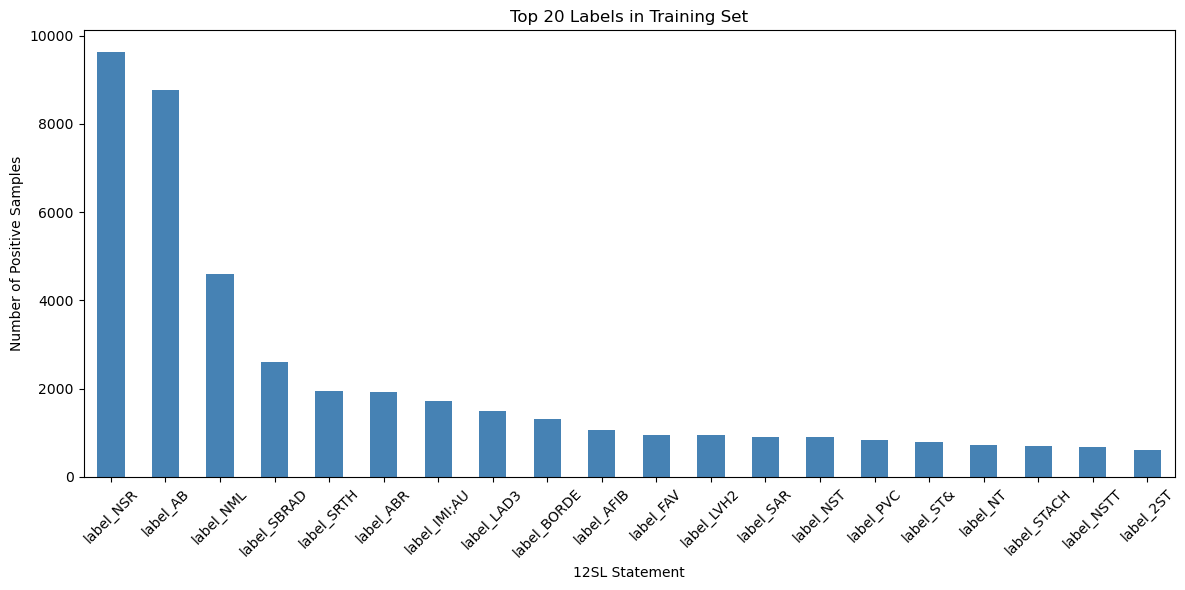

In [13]:
label_cols = [
    col for col in df.columns 
    if col.startswith("label_")
]

label_counts = train_df[label_cols].sum().sort_values(
    ascending=False
)

selected_labels = label_counts[
    label_counts >= 100
].index.tolist()

print("Original labels:", len(label_cols))
print("Selected labels:", len(selected_labels))

plt.figure(figsize=(12, 6))

label_counts.head(20).plot(kind="bar", color="steelblue")

plt.title("Top 20 Labels in Training Set")
plt.ylabel("Number of Positive Samples")
plt.xlabel("12SL Statement")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
def preprocess_ecg(image_path):

    image = Image.open(image_path).convert("RGB")
    image = np.array(image)

    panels = []

    for row in range(4):
        row_panels = []

        for col in range(3):

            x0 = 28 + 390 * col
            x1 = 391 + 390 * col

            y0 = 102 + 280 * row
            y1 = 335 + 280 * row

            panel = image[y0:y1, x0:x1]

            # Extract dark ECG trace and remove red grid
            waveform = (panel[:, :, 0] < 100).astype(
                np.uint8
            ) * 255

            row_panels.append(waveform)

        panels.append(np.concatenate(row_panels, axis=1))

    processed = np.concatenate(panels, axis=0)

    return processed

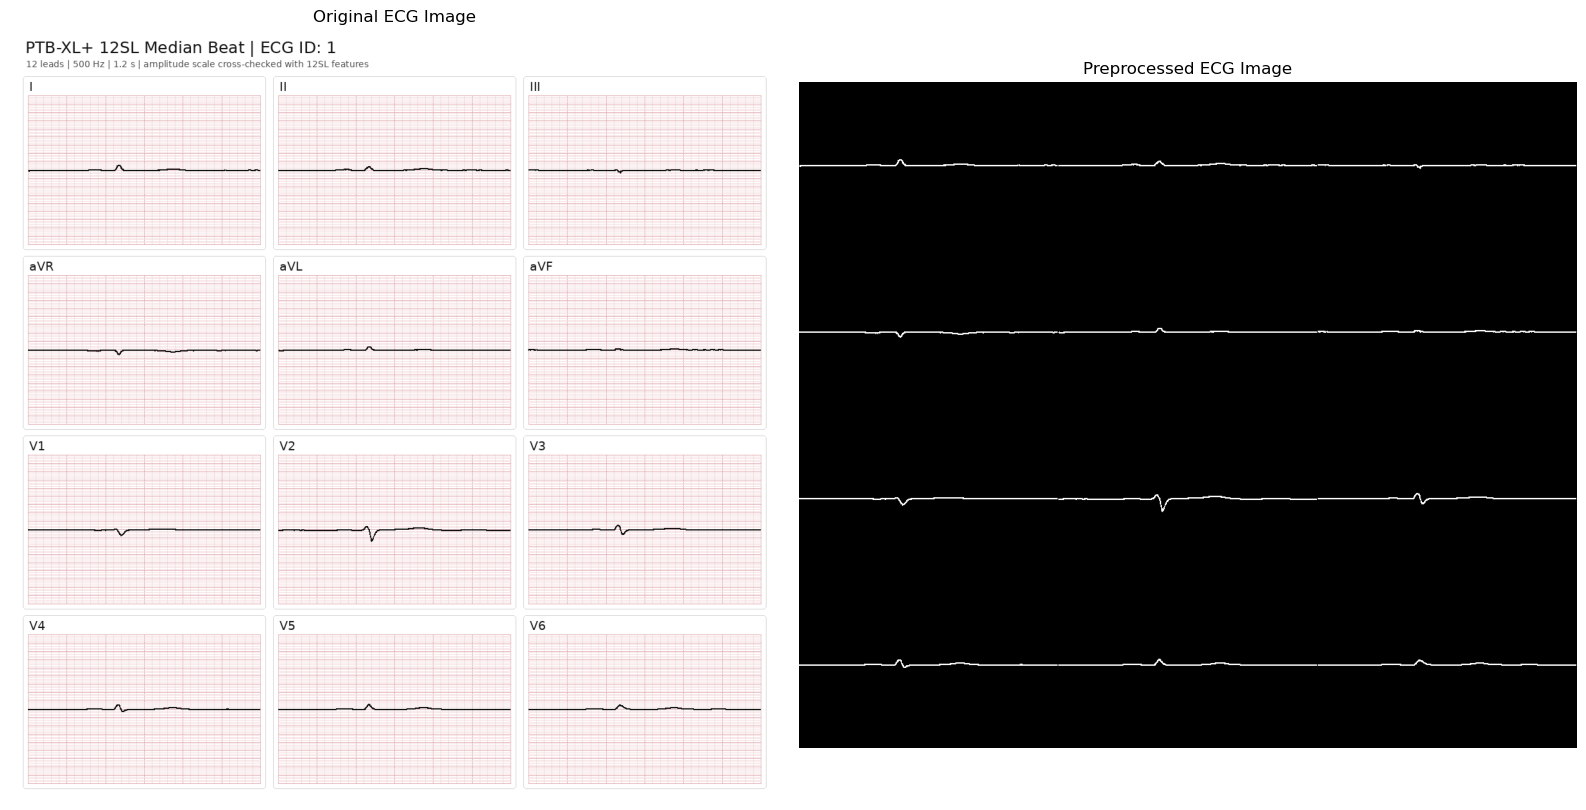

Processed image shape: (932, 1089)


In [15]:
sample = train_df.iloc[0]

image_path = DATA_DIR / sample["image_path"]

original = Image.open(image_path)
processed = preprocess_ecg(image_path)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(original)
axes[0].set_title("Original ECG Image")
axes[0].axis("off")

axes[1].imshow(processed, cmap="gray")
axes[1].set_title("Preprocessed ECG Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Processed image shape:", processed.shape)

In [16]:
distribution = pd.DataFrame({
    "Train": train_df[selected_labels].sum(),
    "Validation": val_df[selected_labels].sum(),
    "Test": test_df[selected_labels].sum()
})

print(distribution)

print("\nLabels without positive validation examples:")
print(distribution[distribution["Validation"] == 0])

print("\nLabels without positive test examples:")
print(distribution[distribution["Test"] == 0])

                Train  Validation  Test
label_NSR        9641        1253  1255
label_AB         8770        1069  1074
label_NML        4590         635   627
label_SBRAD      2594         317   342
label_SRTH       1939         255   265
label_ABR        1931         256   286
label_IMI;AU     1714         196   228
label_LAD3       1495         187   178
label_BORDE      1317         188   171
label_AFIB       1071         129   123
label_FAV         955         105   111
label_LVH2        939         120   118
label_SAR         906         113   140
label_NST         899          96    93
label_PVC         846         115   118
label_ST&         795          88    94
label_NT          726          90   102
label_STACH       704         109    95
label_NSTT        676         108    93
label_2ST         611          81    87
label_LT          602          75    68
label_PAC         545          67    78
label_RBBB        542          73    72
label_SMI;AU      527          65    82


In [17]:
import json

df.to_csv(DATA_DIR / "training_index_with_folds.csv",
          index=False)

with open(DATA_DIR / "selected_labels.json", "w") as f:
    json.dump(selected_labels, f, indent=4)

## Model Training

In [18]:
from skimage.feature import hog
from tqdm.auto import tqdm

from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score
)

import joblib

/usr/lib/python3/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [19]:
def extract_hog_features(image_path):

    image = preprocess_ecg(image_path)

    features = []

    for row in range(4):
        for col in range(3):

            lead = image[
                row * 233 : (row + 1) * 233,
                col * 363 : (col + 1) * 363
            ]

            lead_features = hog(
                lead,
                orientations=9,
                pixels_per_cell=(48, 60),
                cells_per_block=(2, 2),
                block_norm="L2-Hys",
                feature_vector=True
            )

            features.append(lead_features)

    return np.concatenate(features).astype(np.float32)

In [20]:
sample_path = DATA_DIR / train_df.iloc[0]["image_path"]

sample_features = extract_hog_features(sample_path)

print("Original preprocessed shape:",
      preprocess_ecg(sample_path).shape)

print("HOG feature shape:", sample_features.shape)
print("First 20 features:", sample_features[:20])

Original preprocessed shape: (932, 1089)
HOG feature shape: (6480,)
First 20 features: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [21]:
def prepare_features(dataframe, split_name):

    first_image = DATA_DIR / dataframe.iloc[0]["image_path"]
    n_features = len(extract_hog_features(first_image))

    X = np.empty(
        (len(dataframe), n_features),
        dtype=np.float32
    )

    for i, path in enumerate(
        tqdm(dataframe["image_path"],
             desc=f"Extracting {split_name} features")
    ):
        X[i] = extract_hog_features(DATA_DIR / path)

    y = dataframe[selected_labels].to_numpy(
        dtype=np.uint8
    )

    return X, y

In [22]:
X_train, y_train = prepare_features(train_df, "Training")
X_val, y_val = prepare_features(val_df, "Validation")
X_test, y_test = prepare_features(test_df, "Testing")

FEATURE_DIR = DATA_DIR / "hog_features"
FEATURE_DIR.mkdir(exist_ok=True)

np.save(FEATURE_DIR / "X_train.npy", X_train)
np.save(FEATURE_DIR / "X_val.npy", X_val)
np.save(FEATURE_DIR / "X_test.npy", X_test)

np.save(FEATURE_DIR / "y_train.npy", y_train)
np.save(FEATURE_DIR / "y_val.npy", y_val)
np.save(FEATURE_DIR / "y_test.npy", y_test)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Extracting Testing features: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2158/2158 [01:59<00:00, 18.00it/s]


Training: (16608, 6480) (16608, 53)
Validation: (2148, 6480) (2148, 53)
Testing: (2158, 6480) (2158, 53)


## Logistic Regression 

In [26]:
lr_model = OneVsRestClassifier(
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        solver="liblinear",
        random_state=42
    ),
    n_jobs=1
)

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

joblib.dump(lr_model, DATA_DIR / "logistic_regression.pkl")

Logistic Regression training completed.


['data/processed/12sl_median_images_final/logistic_regression.pkl']

In [27]:
lr_val_probs = lr_model.predict_proba(X_val)

lr_val_preds = (lr_val_probs >= 0.5).astype(int)

print("Macro AUROC:",
      roc_auc_score(y_val, lr_val_probs, average="macro"))

print("Macro AUPRC:",
      average_precision_score(y_val, lr_val_probs,
                              average="macro"))

print("Macro F1:",
      f1_score(y_val, lr_val_preds,
               average="macro", zero_division=0))

print("Micro F1:",
      f1_score(y_val, lr_val_preds,
               average="micro", zero_division=0))

Macro AUROC: 0.8651803095001365
Macro AUPRC: 0.33689064773276844
Macro F1: 0.22579528762945886
Micro F1: 0.5839294008360427


# SVM

In [26]:
from sklearn.svm import LinearSVC

In [27]:
svm_model = OneVsRestClassifier(
    LinearSVC(
        C=1.0,
        dual=False,
        max_iter=5000,
        random_state=42
    ),
    n_jobs=1,
    verbose=10
)

In [28]:
svm_model.fit(X_train, y_train)

[Parallel(n_jobs=1)]: Done   1 tasks      | elapsed:    8.6s
[Parallel(n_jobs=1)]: Done   4 tasks      | elapsed:   24.2s
[Parallel(n_jobs=1)]: Done   7 tasks      | elapsed:   44.8s
[Parallel(n_jobs=1)]: Done  12 tasks      | elapsed:  1.1min
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:  1.6min
[Parallel(n_jobs=1)]: Done  24 tasks      | elapsed:  2.0min
[Parallel(n_jobs=1)]: Done  31 tasks      | elapsed:  2.3min
[Parallel(n_jobs=1)]: Done  40 tasks      | elapsed:  2.6min
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:  2.9min
[Parallel(n_jobs=1)]: Done  53 out of  53 | elapsed:  3.0min finished


,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LinearSVC(dua...ndom_state=42)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",1
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",10
Name,Type,Value
"classes_ classes_: array, shape = [`n_classes`]Class labels.","ndarray[int64](53,)","[ 0, 1, 2,...,50,51,52]"
estimators_ estimators_: list of `n_classes` estimatorsEstimators used for predictions.,list,"[LinearSVC(dua...ndom_state=42), LinearSVC(dua...ndom_state=42), LinearSVC(dua...ndom_state=42), LinearSVC(dua...ndom_state=42), ...]"
label_binarizer_ label_binarizer_: LabelBinarizer objectObject used to transform multiclass labels to binary labels andvice-versa.,LabelBinarizer,LabelBinarize...e_output=True)
multilabel_ multilabel_: booleanWhether a OneVsRestClassifier is a multilabel classifier.,bool,True
n_classes_ n_classes_: intNumber of classes.,int,53
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,6480
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",False


In [29]:
print("SVM training completed.")

joblib.dump(
    svm_model,
    DATA_DIR / "linear_svm.pkl"
)

SVM training completed.


['data/processed/12sl_median_images_final/linear_svm.pkl']

In [30]:
svm_val_scores = svm_model.decision_function(X_val)

svm_val_preds = (svm_val_scores >= 0).astype(int)

print("Macro AUROC:",
      roc_auc_score(y_val, svm_val_scores, average="macro"))

print("Macro AUPRC:",
      average_precision_score(y_val, svm_val_scores,
                              average="macro"))

print("Macro F1:",
      f1_score(y_val, svm_val_preds,
               average="macro", zero_division=0))

print("Micro F1:",
      f1_score(y_val, svm_val_preds,
               average="micro", zero_division=0))

Macro AUROC: 0.8536739043754189
Macro AUPRC: 0.33823099141626184
Macro F1: 0.21544564030748195
Micro F1: 0.5893223819301848


## Random Forest

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier

In [30]:
rf_model = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),
    n_jobs=1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

joblib.dump(
    rf_model,
    DATA_DIR / "random_forest.pkl"
)

Random Forest training completed.


['data/processed/12sl_median_images_final/random_forest.pkl']

In [31]:
rf_val_probs = rf_model.predict_proba(X_val)

rf_val_preds = (rf_val_probs >= 0.5).astype(int)

print("Macro AUROC:",
      roc_auc_score(y_val, rf_val_probs, average="macro"))

print("Macro AUPRC:",
      average_precision_score(y_val, rf_val_probs,
                              average="macro"))

print("Macro F1:",
      f1_score(y_val, rf_val_preds,
               average="macro", zero_division=0))

print("Micro F1:",
      f1_score(y_val, rf_val_preds,
               average="micro", zero_division=0))

Macro AUROC: 0.8547229119983855
Macro AUPRC: 0.3219320609037493
Macro F1: 0.14905528905072757
Micro F1: 0.5608154464373224


In [32]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "SVM", "Random Forest"],

    "Macro AUROC": [
        roc_auc_score(y_val, lr_val_probs, average="macro"),
        roc_auc_score(y_val, svm_val_scores, average="macro"),
        roc_auc_score(y_val, rf_val_probs, average="macro")
    ],

    "Macro AUPRC": [
        average_precision_score(y_val, lr_val_probs,
                                average="macro"),
        average_precision_score(y_val, svm_val_scores,
                                average="macro"),
        average_precision_score(y_val, rf_val_probs,
                                average="macro")
    ],

    "Macro F1": [
        f1_score(y_val, lr_val_preds,
                 average="macro", zero_division=0),
        f1_score(y_val, svm_val_preds,
                 average="macro", zero_division=0),
        f1_score(y_val, rf_val_preds,
                 average="macro", zero_division=0)
    ],

    "Micro F1": [
        f1_score(y_val, lr_val_preds, average="micro"),
        f1_score(y_val, svm_val_preds, average="micro"),
        f1_score(y_val, rf_val_preds, average="micro")
    ]
})

display(results.round(4))

,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
0,Logistic Regression,0.8652,0.3369,0.2258,0.5839
1,Random Forest,0.8547,0.3219,0.1491,0.5608


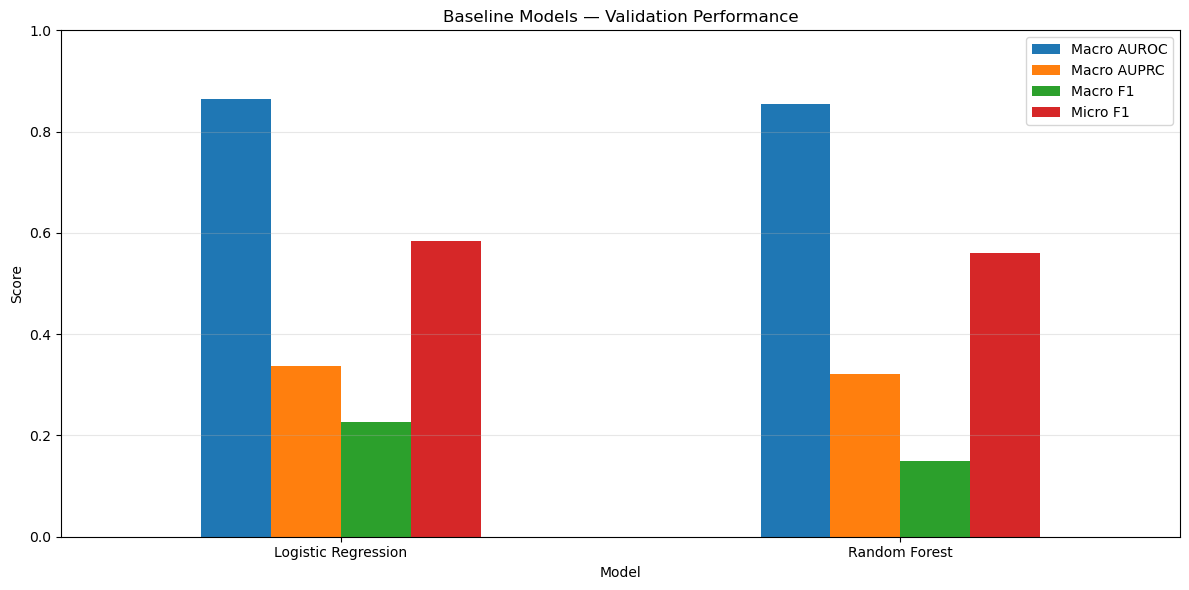

In [33]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Baseline Models — Validation Performance")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 2D CNN

In [34]:
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

In [35]:
torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [36]:
class ECGDataset(Dataset):

    def __init__(self, dataframe, data_dir, labels):

        self.paths = dataframe["image_path"].tolist()
        self.targets = dataframe[labels].to_numpy(
            dtype=np.float32
        )
        self.data_dir = data_dir

    def __len__(self):

        return len(self.paths)

    def __getitem__(self, idx):

        image_path = self.data_dir / self.paths[idx]

        image = preprocess_ecg(image_path)

        leads = []

        for row in range(4):
            for col in range(3):

                panel = image[
                    row * 233 : (row + 1) * 233,
                    col * 363 : (col + 1) * 363
                ]

                leads.append(panel)

        image = np.stack(leads, axis=0)

        image = torch.from_numpy(image).float() / 255.0

        target = torch.from_numpy(self.targets[idx])

        return image, target

In [37]:
train_dataset = ECGDataset(
    train_df, DATA_DIR, selected_labels
)

val_dataset = ECGDataset(
    val_df, DATA_DIR, selected_labels
)

test_dataset = ECGDataset(
    test_df, DATA_DIR, selected_labels
)

In [38]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [39]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

/tmp/ipykernel_15180/3251681603.py:37: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  target = torch.from_numpy(self.targets[idx])


Image batch shape: torch.Size([16, 12, 233, 363])
Label batch shape: torch.Size([16, 53])


In [41]:
class ECGCNN(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        def conv_block(in_channels, out_channels):

            return nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=3,
                    padding=1,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2)
            )

        self.features = nn.Sequential(
            conv_block(12, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256)
        )

        self.pool = nn.AdaptiveAvgPool2d((4, 8))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)

        return x

In [42]:
model = ECGCNN(
    num_classes=len(selected_labels)
).to(device)

print(model)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))

ECGCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(12, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=

In [44]:
EPOCHS = 30
LEARNING_RATE = 0.0003
PATIENCE = 5

In [45]:
criterion = nn.BCEWithLogitsLoss()

In [46]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

In [47]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [48]:
BEST_MODEL_PATH = DATA_DIR / "cnn_best.pt"

In [49]:
print("Training device:", device)
print("Number of classes:", len(selected_labels))

Training device: cuda
Number of classes: 53


In [50]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0.0

    for images, targets in tqdm(loader, desc="Training", leave=False):

        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        # Forward propagation
        logits = model(images)

        # Calculate loss
        loss = criterion(logits, targets)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    return running_loss / len(loader.dataset)

In [51]:
def evaluate_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_targets = []
    all_probs = []

    with torch.no_grad():

        for images, targets in tqdm(
            loader, desc="Evaluating", leave=False
        ):

            images = images.to(device)
            targets = targets.to(device)

            logits = model(images)

            loss = criterion(logits, targets)

            probs = torch.sigmoid(logits)

            running_loss += loss.item() * images.size(0)

            all_targets.append(targets.cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    y_true = np.concatenate(all_targets, axis=0)
    y_probs = np.concatenate(all_probs, axis=0)

    y_preds = (y_probs >= 0.5).astype(int)

    metrics = {
        "loss": running_loss / len(loader.dataset),

        "macro_auroc": roc_auc_score(
            y_true, y_probs, average="macro"
        ),

        "macro_auprc": average_precision_score(
            y_true, y_probs, average="macro"
        ),

        "macro_f1": f1_score(
            y_true, y_preds,
            average="macro", zero_division=0
        ),

        "micro_f1": f1_score(
            y_true, y_preds,
            average="micro", zero_division=0
        )
    }

    return metrics, y_true, y_probs

In [52]:
history = {
    "train_loss": [],
    "val_loss": [],
    "macro_auroc": [],
    "macro_auprc": [],
    "macro_f1": [],
    "micro_f1": []
}

best_auprc = -np.inf
best_epoch = 0
epochs_without_improvement = 0

In [53]:
for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_metrics, _, _ = evaluate_model(
        model,
        val_loader,
        criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_metrics["loss"])
    history["macro_auroc"].append(val_metrics["macro_auroc"])
    history["macro_auprc"].append(val_metrics["macro_auprc"])
    history["macro_f1"].append(val_metrics["macro_f1"])
    history["micro_f1"].append(val_metrics["micro_f1"])

    scheduler.step(val_metrics["macro_auprc"])

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"AUROC: {val_metrics['macro_auroc']:.4f} | "
        f"AUPRC: {val_metrics['macro_auprc']:.4f} | "
        f"Macro F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_auprc"] > best_auprc:

        best_auprc = val_metrics["macro_auprc"]
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        epochs_without_improvement = 0

        print("Best model saved.")

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("Early stopping triggered.")
        break

Epoch [01/30] | Train Loss: 0.1495 | Val Loss: 0.1181 | AUROC: 0.8464 | AUPRC: 0.2562 | Macro F1: 0.1105
Best model saved.


Epoch [02/30] | Train Loss: 0.1182 | Val Loss: 0.1078 | AUROC: 0.8745 | AUPRC: 0.3273 | Macro F1: 0.1575
Best model saved.


Epoch [03/30] | Train Loss: 0.1084 | Val Loss: 0.1019 | AUROC: 0.8920 | AUPRC: 0.3694 | Macro F1: 0.2073
Best model saved.


Epoch [04/30] | Train Loss: 0.1024 | Val Loss: 0.0972 | AUROC: 0.9002 | AUPRC: 0.3977 | Macro F1: 0.2200
Best model saved.


Epoch [05/30] | Train Loss: 0.0985 | Val Loss: 0.0931 | AUROC: 0.9088 | AUPRC: 0.4098 | Macro F1: 0.2458
Best model saved.


Epoch [06/30] | Train Loss: 0.0954 | Val Loss: 0.0921 | AUROC: 0.9126 | AUPRC: 0.4285 | Macro F1: 0.2496
Best model saved.


... (19 outputs left out)

Epoch [26/30] | Train Loss: 0.0529 | Val Loss: 0.1121 | AUROC: 0.9200 | AUPRC: 0.4825 | Macro F1: 0.3560


Epoch [27/30] | Train Loss: 0.0513 | Val Loss: 0.1058 | AUROC: 0.9225 | AUPRC: 0.4839 | Macro F1: 0.3718


Epoch [28/30] | Train Loss: 0.0437 | Val Loss: 0.1114 | AUROC: 0.9207 | AUPRC: 0.4853 | Macro F1: 0.3800


Epoch [29/30] | Train Loss: 0.0416 | Val Loss: 0.1137 | AUROC: 0.9205 | AUPRC: 0.4882 | Macro F1: 0.3862
Early stopping triggered.


In [54]:
print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation Macro AUPRC:", best_auprc)


Training completed.
Best epoch: 24
Best validation Macro AUPRC: 0.48958893864040115


In [55]:
history_df = pd.DataFrame(history)

history_df.to_csv(
    DATA_DIR / "cnn_training_history.csv",
    index=False
)

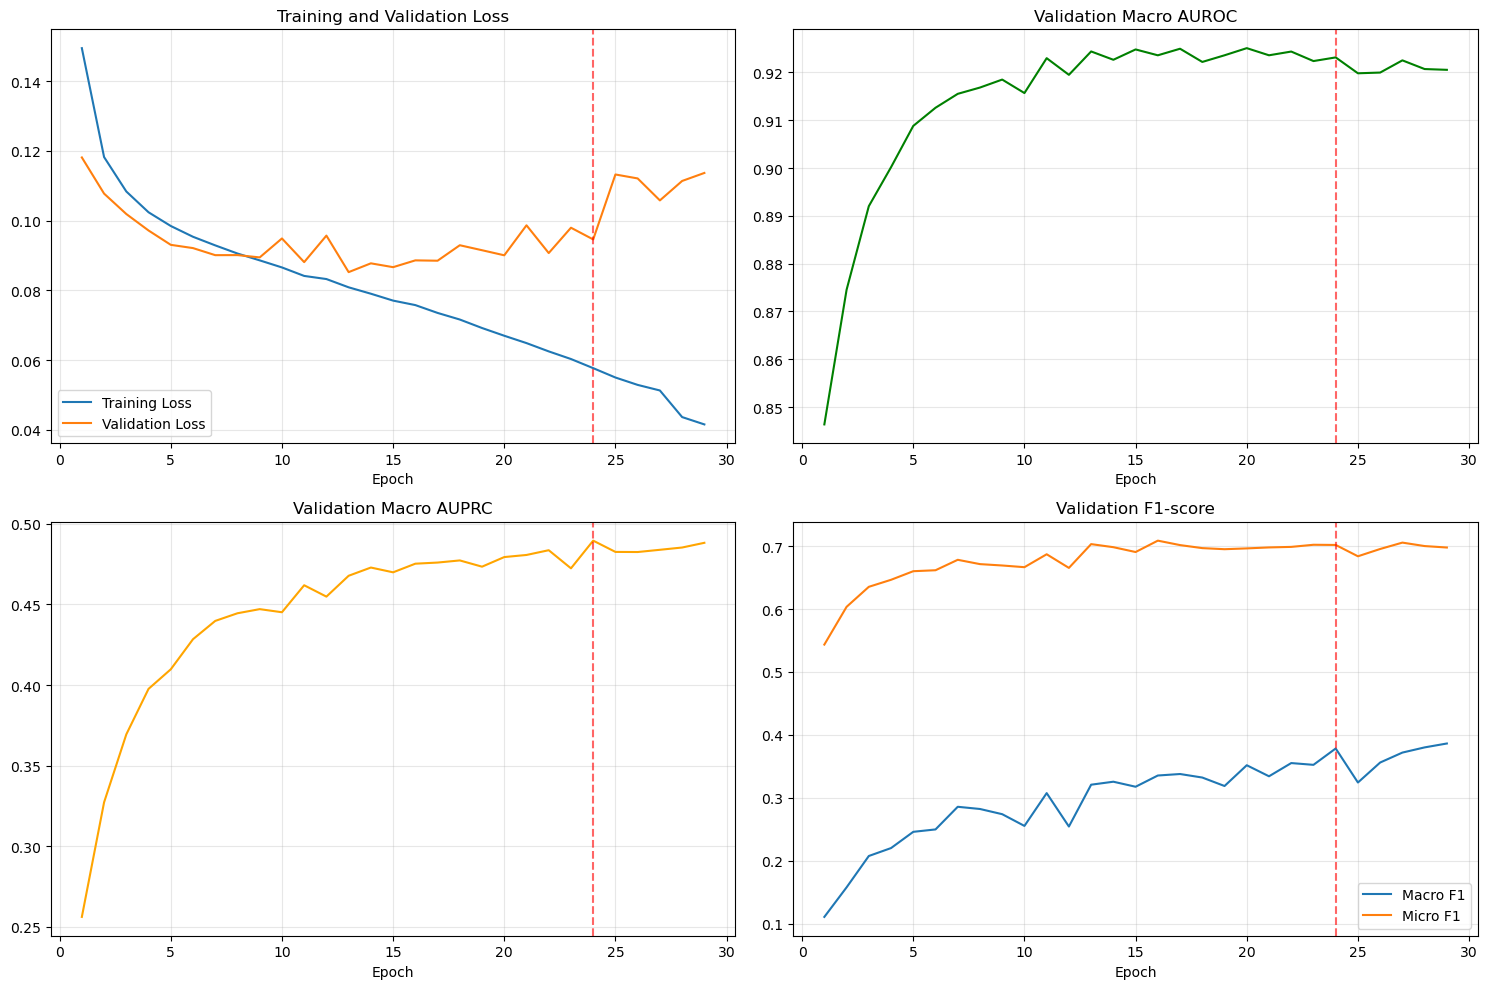

In [56]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Loss
axes[0, 0].plot(
    epochs, history["train_loss"], label="Training Loss"
)
axes[0, 0].plot(
    epochs, history["val_loss"], label="Validation Loss"
)
axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].legend()

# AUROC
axes[0, 1].plot(
    epochs, history["macro_auroc"], color="green"
)
axes[0, 1].set_title("Validation Macro AUROC")

# AUPRC
axes[1, 0].plot(
    epochs, history["macro_auprc"], color="orange"
)
axes[1, 0].set_title("Validation Macro AUPRC")

# F1
axes[1, 1].plot(
    epochs, history["macro_f1"], label="Macro F1"
)
axes[1, 1].plot(
    epochs, history["micro_f1"], label="Micro F1"
)
axes[1, 1].set_title("Validation F1-score")
axes[1, 1].legend()

for ax in axes.flat:

    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.axvline(
        best_epoch,
        color="red",
        linestyle="--",
        alpha=0.6
    )

plt.tight_layout()
plt.show()

In [57]:
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

model.to(device)

cnn_metrics, cnn_val_targets, cnn_val_probs = evaluate_model(
    model,
    val_loader,
    criterion
)

cnn_val_preds = (cnn_val_probs >= 0.5).astype(int)

assert np.array_equal(cnn_val_targets, y_val)

print("Best CNN Validation Results")
print("-" * 40)

for metric, value in cnn_metrics.items():

    print(f"{metric}: {value:.4f}")

Best CNN Validation Results
----------------------------------------
loss: 0.0946
macro_auroc: 0.9231
macro_auprc: 0.4896
macro_f1: 0.3783
micro_f1: 0.7018


,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
0,Logistic Regression,0.8652,0.3369,0.2258,0.5839
1,Random Forest,0.8547,0.3219,0.1491,0.5608
2,2D CNN,0.9231,0.4896,0.3783,0.7018


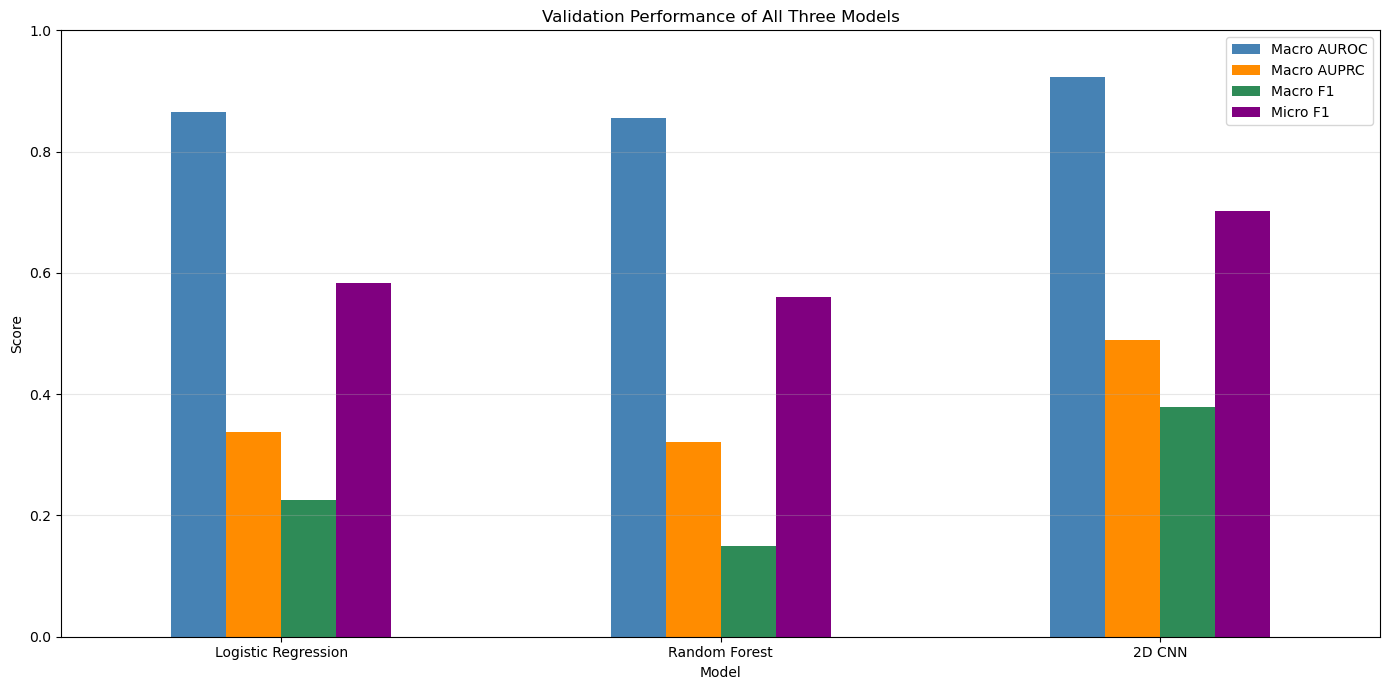

In [58]:
cnn_results = pd.DataFrame([{
    "Model": "2D CNN",
    "Macro AUROC": cnn_metrics["macro_auroc"],
    "Macro AUPRC": cnn_metrics["macro_auprc"],
    "Macro F1": cnn_metrics["macro_f1"],
    "Micro F1": cnn_metrics["micro_f1"]
}])

final_val_results = pd.concat(
    [results, cnn_results],
    ignore_index=True
)

display(final_val_results.round(4))

final_val_results.to_csv(
    DATA_DIR / "validation_model_comparison.csv",
    index=False
)

final_val_results.set_index("Model").plot(
    kind="bar",
    figsize=(14, 7),
    ylim=(0, 1),
    rot=0,
    color=["steelblue", "darkorange", "seagreen", "purple"]
)

plt.title("Validation Performance of All Three Models")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()